<h1>Train — ConvNeXt-Tiny</h1>

Trains and evaluates ConvNeXt-Tiny using the tuned hyperparameters from `ARCH_HYPERPARAMS["convnext_tiny"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']
Train: 947 | Val: 229 | Test: 567


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["convnext_tiny"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ConvNeXt-Tiny: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ConvNeXt-Tiny: micro batch = 8, accumulation steps = 1 (effective batch size ≈ 8, tuned value = 8)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with ConvNeXt-Tiny)
# ---------------------------------------------------------
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)

model.avgpool = nn.AdaptiveMaxPool2d(1)

in_f = model.classifier[2].in_features
model.classifier[2] = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
# criterion = FocalLoss(weight=class_weights_arch, gamma=2.0)  # parked for later -- see todo.txt

optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)

scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ConvNeXt-Tiny] Epoch   1/100 | LR: 6.78e-05 | train loss 0.9153 acc 0.630 | val loss 0.7010 acc 0.721 *


[ConvNeXt-Tiny] Epoch   2/100 | LR: 6.78e-05 | train loss 0.7069 acc 0.735 | val loss 0.5546 acc 0.782 *


[ConvNeXt-Tiny] Epoch   3/100 | LR: 6.78e-05 | train loss 0.6732 acc 0.755 | val loss 0.7285 acc 0.672


[ConvNeXt-Tiny] Epoch   4/100 | LR: 6.78e-05 | train loss 0.5454 acc 0.810 | val loss 0.7829 acc 0.681


[ConvNeXt-Tiny] Epoch   5/100 | LR: 6.78e-05 | train loss 0.5338 acc 0.786 | val loss 0.5496 acc 0.777 *


...

[ConvNeXt-Tiny] Epoch  18/100 | LR: 6.78e-05 | train loss 0.1266 acc 0.961 | val loss 0.7373 acc 0.790


[ConvNeXt-Tiny] Epoch  19/100 | LR: 6.78e-05 | train loss 0.1812 acc 0.944 | val loss 0.5917 acc 0.852


[ConvNeXt-Tiny] Epoch  20/100 | LR: 6.78e-05 | train loss 0.1113 acc 0.957 | val loss 0.5788 acc 0.817


[ConvNeXt-Tiny] Epoch  21/100 | LR: 6.78e-05 | train loss 0.1132 acc 0.964 | val loss 0.7670 acc 0.747


[ConvNeXt-Tiny] Epoch  22/100 | LR: 6.78e-05 | train loss 0.0610 acc 0.979 | val loss 1.0753 acc 0.773

[ConvNeXt-Tiny] No val loss improvement for 10 epochs — stopping early at epoch 22.

[ConvNeXt-Tiny] Restored best checkpoint (val loss = 0.4714)


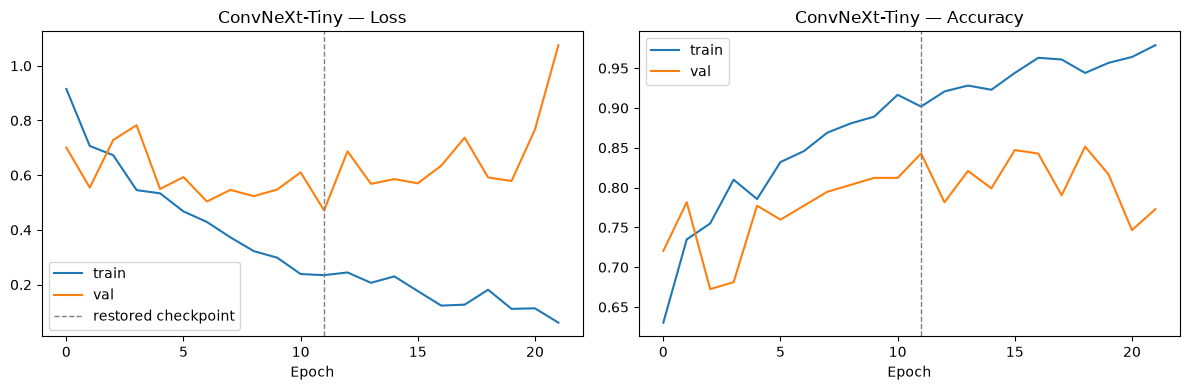

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ConvNeXt-Tiny", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ConvNeXt-Tiny")

## Evaluate on the test set

[ConvNeXt-Tiny] Test accuracy: 0.850


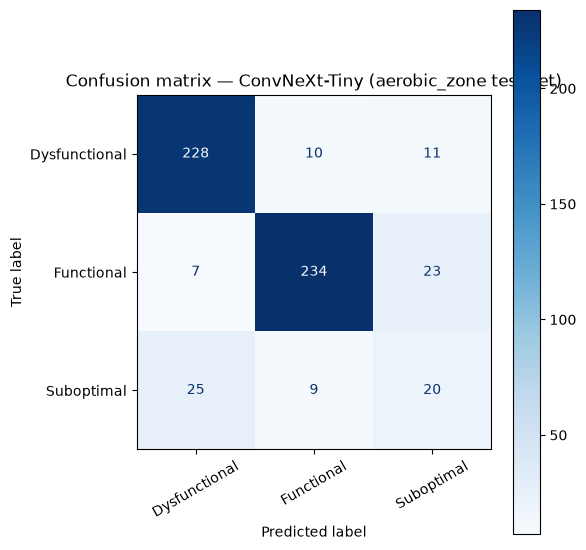

               precision    recall  f1-score   support

Dysfunctional      0.877     0.916     0.896       249
   Functional      0.925     0.886     0.905       264
   Suboptimal      0.370     0.370     0.370        54

     accuracy                          0.850       567
    macro avg      0.724     0.724     0.724       567
 weighted avg      0.851     0.850     0.850       567



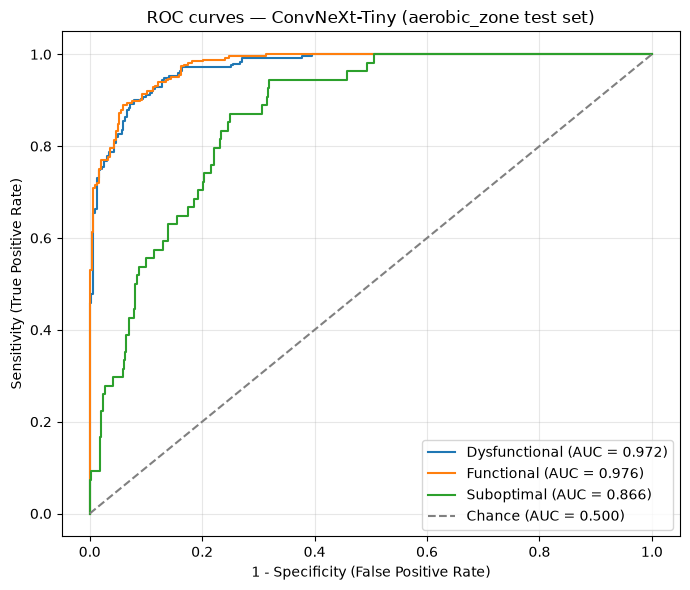

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.972
  Functional     : 0.976
  Suboptimal     : 0.866

Mean AUC (over 3/3 classes with test examples): 0.938


(np.float64(0.8500881834215167),
 {'Dysfunctional': 0.972228536788664,
  'Functional': 0.9764726472647265,
  'Suboptimal': 0.8656775684066133})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ConvNeXt-Tiny", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("ConvNeXt-Tiny", "convnext_tiny")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_convnext_tiny_chronological.pkl
Saved model weights to ../models/pad/aerobic_zone_convnext_tiny_cnn.pt
